In [1]:
# The proposed system: two-branch CNN-LSTM over pressure and inertial channels
# ===========================================================================
# Fusion-Design-Test.ipynb established that the published single-stream design
# was the limiting factor, not the sensing. Concatenating all channels into one
# encoder let one modality dominate the first convolution; giving each modality
# its own encoder and joining them at the embedding reached 0.179% EER at W = 5
# against 0.701% for the published pipeline, better in nine folds out of nine
# (Wilcoxon p = 0.0039). It also beat a per-fold oracle over the two single
# modality models (0.587%), which means the two branches are combining rather
# than one of them merely being selected.
#
# This notebook makes that design the proposed system and regenerates everything
# the manuscript reports from it:
#
#   Part A   the full impostor rotation                 -> Table 1, Figures 7-8
#   Part B   a capacity control                         -> answers "is it just
#                                                          twice the parameters?"
#   Part C   the single-configuration protocol          -> the proposed row of
#                                                          Table 2
#   Part D   the feature-window sweep                   -> Table 3
#
# One point should be stated before any of it runs. The two-branch model is
# given the hyperparameters that an earlier search selected for the single
# stream model -- hidden size 64, two layers, dropout 0.395, learning rate
# 1.814e-3 -- and is not tuned again. It therefore wins without any tuning
# advantage over the design it replaces, and if anything the figures below
# understate it. Section III-E of the manuscript should say so.

In [2]:
# Part 1: Imports, device selection, and experiment configuration
# ---------------------------------------------------------------------------
# This notebook supersedes the single-session version. Every recording folder
# found under DATA_ROOT/<participant>/ is used, and the train / validation /
# test partitions are kept disjoint (see PROTOCOL below).

import os
import copy
import json
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import roc_curve, auc

warnings.filterwarnings('ignore')

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print(f"Using device: {DEVICE}")

# ---------------------------------------------------------------------------
# Data location and participant roster
# ---------------------------------------------------------------------------
DATA_ROOT = './data'
PARTICIPANTS = ['P01', 'P02', 'P03', 'P04', 'P05',
                'P06', 'P07', 'P08', 'P09', 'P10']

# Recording folders captured on the LAPTOP keyboard. These form the
# cross-domain test condition for whichever participant is the genuine user.
# Everything not listed here is treated as desktop (training-domain) data.
# Extend this dict as further laptop sessions are recorded.
LAPTOP_FOLDERS = {
    'P01': ['202602041210'],
}

# ---------------------------------------------------------------------------
# Local, non-anonymized override
# ---------------------------------------------------------------------------
# participants_local.json holds the real on-disk folder names, so the notebooks
# run against the collected data without renaming anything. It is gitignored:
# the ids are student numbers and are directly identifying. When the file is
# absent -- the state the public repository should always be in -- the
# anonymized P01-P10 roster above is used instead.
#
# Every table, CSV and figure below is written using ANON_LABEL, so output
# produced from the real data is already anonymized and can go straight into
# the manuscript.
LOCAL_CONFIG = 'participants_local.json'
ANON_LABEL = {}
DEFAULT_GENUINE = 'P01'
DEFAULT_HELDOUT = 'P10'

if os.path.exists(LOCAL_CONFIG):
    with open(LOCAL_CONFIG, encoding='utf-8') as _f:
        _cfg = json.load(_f)
    PARTICIPANTS = list(_cfg['participants'])
    LAPTOP_FOLDERS = dict(_cfg.get('laptop_folders', {}))
    ANON_LABEL = dict(_cfg.get('labels', {}))
    DEFAULT_GENUINE = _cfg.get('default_genuine', PARTICIPANTS[0])
    DEFAULT_HELDOUT = _cfg.get('default_heldout_impostor', PARTICIPANTS[-1])
    print(f"Loaded {LOCAL_CONFIG}: {len(PARTICIPANTS)} participants "
          f"(output will be labelled {ANON_LABEL.get(PARTICIPANTS[0], '?')}"
          f"-{ANON_LABEL.get(PARTICIPANTS[-1], '?')})")
else:
    print(f"{LOCAL_CONFIG} not found -- using the anonymized roster.")


def label(pid):
    """Anonymized display name for a participant id."""
    return ANON_LABEL.get(pid, pid)

# ---------------------------------------------------------------------------
# Protocol switches
# ---------------------------------------------------------------------------
# STRICT_PROTOCOL = True  -> early stopping uses a validation split drawn only
#                            from the training domain; the reported EER is
#                            computed on a test set the model never saw.
# STRICT_PROTOCOL = False -> reproduces the original notebooks, where the same
#                            loader served as both the early-stopping validation
#                            set and the reported evaluation set (and included
#                            the held-out impostor). Kept only for comparison.
STRICT_PROTOCOL = True

# The manuscript states that the first repetition of each recording is dropped
# for device habituation. The original notebooks applied this to sentence '1'
# only, and that is kept as the default here: in the collected data the other
# sentences are a single take whose session_count never exceeds 1, so filtering
# them on session_count > 1 discards those recordings entirely and silently.
# Set to None to apply the filter to every sentence -- but check the data-yield
# table printed by preflight() first, and reconcile the wording in the
# manuscript with whichever setting is used.
FIRST_REPETITION_SENTENCES = {'1'}

TRAIN_RATIO = 0.8          # chronological split inside each recording unit
SENTENCE_IDS = ['1', '2', '3']

ALL_SENSOR_COLS = [
    'R_S_1', 'R_S_2', 'R_S_3', 'R_S_4', 'R_S_5',
    'R_S_6', 'R_S_7', 'R_S_8', 'R_S_9', 'R_S_10',
    'R_Gyro_X', 'R_Gyro_Y', 'R_Gyro_Z',
    'R_Accel_X', 'R_Accel_Y', 'R_Accel_Z',
    'R_Mag_X', 'R_Mag_Y', 'R_Mag_Z',
]
N_CHANNELS = len(ALL_SENSOR_COLS)
print(f"Sensor channels: {N_CHANNELS}")


Using device: mps
Loaded participants_local.json: 10 participants (output will be labelled P01-P10)
Sensor channels: 19


In [3]:
# Part 2: Data layer
# ---------------------------------------------------------------------------
# Session discovery, per-unit loading, windowing, splitting, group-aware
# smoothing and metrics. A "unit" is one (participant, folder, sentence)
# recording. Building features per unit guarantees that no feature window ever
# spans two recordings and gives each test segment a natural smoothing group.

def discover_sessions(root_dir, pid):
    """Every recording folder for `pid` holding at least one usable sentence.
    Folder names are yyyymmddHHMM stamps, so sorting is chronological."""
    pdir = os.path.join(root_dir, pid)
    if not os.path.isdir(pdir):
        return []
    found = []
    for name in sorted(os.listdir(pdir)):
        fdir = os.path.join(pdir, name)
        if not os.path.isdir(fdir):
            continue
        for s_id in SENTENCE_IDS:
            g = os.path.join(fdir, s_id, f"{pid}_{s_id}_glove_R.csv")
            k = os.path.join(fdir, s_id, f"{pid}_{s_id}_kb.csv")
            if os.path.exists(g) and os.path.exists(k):
                found.append(name)
                break
    return found


def load_unit(root_dir, pid, folder, s_id, drop_first_repetition=True):
    sdir = os.path.join(root_dir, pid, folder, s_id)
    gpath = os.path.join(sdir, f"{pid}_{s_id}_glove_R.csv")
    kpath = os.path.join(sdir, f"{pid}_{s_id}_kb.csv")
    if not (os.path.exists(gpath) and os.path.exists(kpath)):
        return None, None
    try:
        g_df = pd.read_csv(gpath)
        k_df = pd.read_csv(kpath)
    except Exception:
        return None, None
    if drop_first_repetition:
        if 'session_count' in g_df.columns:
            g_df = g_df[g_df['session_count'] > 1]
        if 'session_count' in k_df.columns:
            k_df = k_df[k_df['session_count'] > 1]
    if g_df.empty or k_df.empty:
        return None, None
    return g_df.reset_index(drop=True), k_df.reset_index(drop=True)


def clip_pressure_outliers(glove_df, threshold=1000.0):
    """Clip nonphysical readings to the largest valid value in this unit.
    Returns a copy: the original notebooks mutated the caller's DataFrame, so
    clipped values leaked across window-length settings and across folds."""
    out = glove_df.copy()
    for col in [c for c in ALL_SENSOR_COLS if c.startswith('R_S_')]:
        if col not in out.columns:
            continue
        vals = out[col].values.astype(np.float64)
        valid = vals < threshold
        if np.any(valid):
            out.loc[out[col] >= threshold, col] = float(np.max(vals[valid]))
    return out


def _interpolate(features, target_len):
    x = np.linspace(0, 1, features.shape[0])
    x_new = np.linspace(0, 1, target_len)
    return interp1d(x, features, axis=0, kind='linear',
                    fill_value="extrapolate")(x_new)


def build_windows(glove_df, kb_df, window_ms, target_len, min_samples=5):
    """One normalized window per keystroke -> (N, target_len, 19).
    Z-score normalization is per window and per channel (over time)."""
    g = clip_pressure_outliers(glove_df)
    order = np.argsort(g['glove_timestamp'].values, kind='stable')
    glove_ts = g['glove_timestamp'].values[order]
    glove_vals = g[ALL_SENSOR_COLS].values.astype(np.float32)[order]
    kb_ts = np.sort(kb_df['kb_timestamp_pressed'].values)

    half = window_ms / 2000.0
    out = []
    for ts in kb_ts:
        i0 = np.searchsorted(glove_ts, ts - half, side='left')
        i1 = np.searchsorted(glove_ts, ts + half, side='right')
        seg = glove_vals[i0:i1]
        if len(seg) < min_samples:
            continue
        out.append(_interpolate(seg, target_len))

    if not out:
        return np.empty((0, target_len, N_CHANNELS), dtype=np.float32)
    arr = np.asarray(out, dtype=np.float32)
    mean = arr.mean(axis=1, keepdims=True)
    std = arr.std(axis=1, keepdims=True)
    std[std < 1e-6] = 1e-6
    return (arr - mean) / std


def chronological_split(n, train_ratio=TRAIN_RATIO):
    """Time-preserving index split, applied *inside* one unit.
    This replaces chronological_split_per_text(), which cut the concatenated
    array into three equal blocks -- an assumption that silently breaks as soon
    as more than one recording folder is loaded."""
    n_train = int(n * train_ratio)
    return np.arange(0, n_train), np.arange(n_train, n)


def chronological_split3(n, ratios=(0.6, 0.2, 0.2)):
    """Time-preserving 3-way index split inside one recording unit.
    Used only by the hyperparameter search, which needs its own held-out
    portion of the *training domain* so that the real test set stays untouched."""
    a = int(n * ratios[0])
    b = a + int(n * ratios[1])
    return np.arange(0, a), np.arange(a, b), np.arange(b, n)


def smooth_within_group(scores, window_size):
    scores = np.asarray(scores, dtype=np.float64)
    if window_size <= 1:
        return scores
    if len(scores) < window_size:
        return np.empty((0,), dtype=np.float64)
    csum = np.cumsum(np.insert(scores, 0, 0.0))
    return (csum[window_size:] - csum[:-window_size]) / float(window_size)


def smooth_grouped(scores, labels, groups, window_size):
    """Moving average applied separately within each recording unit.
    The original reset its buffer only when the *label* changed, so scores from
    consecutive impostors (both label 0) were averaged across subject
    boundaries, manufacturing samples that belong to no one."""
    scores, labels = np.asarray(scores), np.asarray(labels)
    # Build a flat 1-D object array explicitly: np.asarray() on a list of
    # tuples would produce a 2-D array and make the comparisons element-wise.
    g = np.empty(len(groups), dtype=object)
    for i, v in enumerate(groups):
        g[i] = v
    groups = g
    out_s, out_l, start = [], [], 0
    for i in range(1, len(groups) + 1):
        if i == len(groups) or groups[i] != groups[start]:
            sm = smooth_within_group(scores[start:i], window_size)
            if len(sm):
                out_s.append(sm)
                out_l.append(np.full(len(sm), labels[start]))
            start = i
    if not out_s:
        return np.empty((0,)), np.empty((0,))
    return np.concatenate(out_s), np.concatenate(out_l)


def eer_and_metrics(y_true, y_score, target_far=0.001):
    """EER as the mean of FPR and FNR at the crossing point. The original
    reported FPR alone, which is biased low on a coarse ROC grid."""
    y_true, y_score = np.asarray(y_true), np.asarray(y_score)
    nan = dict(eer=np.nan, auc=np.nan, frr_at_far=np.nan, threshold=np.nan)
    # A diverged model produces non-finite scores; report them as undefined
    # rather than letting roc_curve raise several frames away from the cause.
    if len(y_score) == 0 or not np.all(np.isfinite(y_score)):
        return nan
    if len(np.unique(y_true)) < 2:
        return nan
    fpr, tpr, thr = roc_curve(y_true, y_score, pos_label=1)
    fnr = 1.0 - tpr
    idx = int(np.nanargmin(np.abs(fnr - fpr)))
    try:
        frr = float(1.0 - interp1d(fpr, tpr, kind='linear')(target_far))
    except Exception:
        cand = np.where(fpr >= target_far)[0]
        frr = float(1.0 - tpr[cand[0]]) if len(cand) else 1.0
    return dict(eer=float((fpr[idx] + fnr[idx]) / 2.0),
                auc=float(auc(fpr, tpr)),
                frr_at_far=float(max(0.0, min(1.0, frr))),
                threshold=float(thr[idx]))


def smoothing_table(probs, labels, groups, windows):
    """EER / AUC / FRR@FAR=0.1% for an arbitrary set of smoothing windows,
    computed from stored per-keystroke scores. No retraining required."""
    rows = []
    for w in windows:
        sc, lb = smooth_grouped(probs, labels, groups, w)
        m = (eer_and_metrics(lb, sc) if len(lb)
             else dict(eer=np.nan, auc=np.nan, frr_at_far=np.nan))
        rows.append({'W': w, 'n_scores': len(lb), **m})
    return pd.DataFrame(rows)


class BoundedFoldCache(dict):
    """LRU-bounded cache of built folds.

    Each fold holds roughly 75 MB of float32 features on this dataset, and the
    key space is heldout x sentence x window_ms x target_len. Caching without a
    bound would reach several GB partway through a search.
    """
    def __init__(self, maxsize=6):
        super().__init__()
        self.maxsize = maxsize
        self._order = []

    def get_or_build(self, key, build):
        if key in self:
            self._order.remove(key)
            self._order.append(key)
            return self[key]
        val = build()
        self[key] = val
        self._order.append(key)
        while len(self._order) > self.maxsize:
            del self[self._order.pop(0)]
        return val


def separation_margin(gen_scores, imp_scores, q_gen=0.01, q_imp=0.99):
    """Gap between the genuine lower tail and the impostor upper tail.

    Retains resolution when the two classes are perfectly separated and EER is
    exactly 0, which is where EER stops being able to rank anything.
    """
    gen_scores = np.asarray(gen_scores, float)
    imp_scores = np.asarray(imp_scores, float)
    if len(gen_scores) == 0 or len(imp_scores) == 0:
        return float('nan')
    return float(np.quantile(gen_scores, q_gen) - np.quantile(imp_scores, q_imp))


TIE_BREAK_WEIGHT = 1e-4   # must stay below one test sample's worth of EER

def tuning_objective(eer, margin, weight=TIE_BREAK_WEIGHT):
    """EER, with a margin term that only decides exact ties.

    An inner fold can separate perfectly, in which case every configuration
    scores 0.000% and the search has nothing to optimise. The added term is
    bounded by `weight`, which is smaller than the EER step of a single test
    sample, so a measurable EER difference always outranks it.
    """
    if not np.isfinite(eer):
        return float('inf')
    m = 0.0 if not np.isfinite(margin) else float(np.clip(margin, -1.0, 1.0))
    return float(eer) + weight * (1.0 - m) / 2.0


def mean_sd(values, ddof=1):
    """Sample standard deviation. The original used np.std's default ddof=0,
    which understates the spread at n=5 by about 12%."""
    v = np.asarray([x for x in values if x is not None and not np.isnan(x)], float)
    if len(v) == 0:
        return float('nan'), float('nan')
    if len(v) == 1:
        return float(v[0]), 0.0
    return float(v.mean()), float(v.std(ddof=ddof))


In [4]:
# Part 3: Discover every session and print the inventory
# ---------------------------------------------------------------------------
# Check this table before running anything: it is the ground truth for how many
# sessions actually entered the experiment, and the figure that belongs in the
# manuscript's dataset description.

def diagnose_data_root(max_show=8):
    """Explain why discovery found nothing.

    Expected layout:
        DATA_ROOT/<participant>/<yyyymmddHHMM>/<sentence 1|2|3>/
            <participant>_<sentence>_glove_R.csv
            <participant>_<sentence>_kb.csv
    """
    print("-" * 70)
    print("DATA LAYOUT DIAGNOSTIC")
    print("-" * 70)
    print(f"DATA_ROOT           : {DATA_ROOT!r}")
    print(f"resolves to         : {os.path.abspath(DATA_ROOT)}")
    print(f"notebook cwd        : {os.getcwd()}")
    print(f"exists              : {os.path.isdir(DATA_ROOT)}")
    if not os.path.isdir(DATA_ROOT):
        here = sorted(d for d in os.listdir('.') if os.path.isdir(d))[:max_show]
        print(f"\nDirectories next to the notebook: {here}")
        print("\n-> Point DATA_ROOT at the folder that contains the per-participant")
        print("   directories, e.g. DATA_ROOT = '/absolute/path/to/data'.")
        return

    entries = sorted(os.listdir(DATA_ROOT))
    subdirs = [d for d in entries if os.path.isdir(os.path.join(DATA_ROOT, d))]
    print(f"\nSubdirectories ({len(subdirs)}): {subdirs[:max_show]}"
          f"{' ...' if len(subdirs) > max_show else ''}")
    print(f"Roster expects      : {PARTICIPANTS[:max_show]}"
          f"{' ...' if len(PARTICIPANTS) > max_show else ''}")
    matched = [p for p in PARTICIPANTS if p in subdirs]
    print(f"Roster names present: {matched if matched else 'NONE'}")
    if not matched and subdirs:
        print("\n-> The roster does not match the directory names on disk.")
        print("   Either edit PARTICIPANTS, or put the real ids in")
        print(f"   {LOCAL_CONFIG} (searched at {os.path.abspath(LOCAL_CONFIG)}).")

    probe = (matched or subdirs)[:1]
    for pid in probe:
        pdir = os.path.join(DATA_ROOT, pid)
        folders = sorted(d for d in os.listdir(pdir)
                         if os.path.isdir(os.path.join(pdir, d)))
        print(f"\n{pid}/ contains {len(folders)} folders: {folders[:max_show]}")
        for folder in folders[:1]:
            fdir = os.path.join(pdir, folder)
            inner = sorted(os.listdir(fdir))
            print(f"  {folder}/ -> {inner[:max_show]}   (expected {SENTENCE_IDS})")
            for s_id in inner[:1]:
                sdir = os.path.join(fdir, s_id)
                if os.path.isdir(sdir):
                    files = sorted(os.listdir(sdir))
                    print(f"    {s_id}/ -> {files[:max_show]}")
                    print(f"    expected: {pid}_{s_id}_glove_R.csv  and  {pid}_{s_id}_kb.csv")
    print("-" * 70)


SESSIONS = {pid: discover_sessions(DATA_ROOT, pid) for pid in PARTICIPANTS}

if not any(SESSIONS.values()):
    diagnose_data_root()
    raise FileNotFoundError(
        "No recording sessions were discovered under DATA_ROOT. See the "
        "diagnostic above; fix DATA_ROOT (or the participant roster) and rerun "
        "this cell before continuing.")

rows = []
for pid in PARTICIPANTS:
    laptop = [f for f in SESSIONS[pid] if f in LAPTOP_FOLDERS.get(pid, [])]
    desktop = [f for f in SESSIONS[pid] if f not in laptop]
    rows.append({'participant': label(pid),
                 'n_folders': len(SESSIONS[pid]),
                 'n_desktop': len(desktop),
                 'n_laptop': len(laptop),
                 'folders': ', '.join(SESSIONS[pid]) if SESSIONS[pid] else '(none found)'})
inventory = pd.DataFrame(rows)
print(inventory.to_string(index=False))

n_folders = int(inventory['n_folders'].sum())
n_units = n_folders * len(SENTENCE_IDS)
print(f"\nTotal recording folders : {n_folders}")
print(f"Total sentence units    : {n_units}  ({n_folders} folders x {len(SENTENCE_IDS)} sentences)")
missing = [label(p) for p in PARTICIPANTS if not SESSIONS[p]]
if missing:
    print(f"WARNING: no data found for {missing} -- check DATA_ROOT.")

# ---------------------------------------------------------------------------
# Which participants can serve as the genuine user?
# ---------------------------------------------------------------------------
# A genuine user needs two domains: training-domain (desktop) sessions and at
# least one cross-domain (laptop) session held out for testing. A participant
# with a single recording folder cannot supply both, so they can only ever act
# as an impostor.
def can_be_genuine(pid):
    laptop = [f for f in SESSIONS[pid] if f in LAPTOP_FOLDERS.get(pid, [])]
    desktop = [f for f in SESSIONS[pid] if f not in laptop]
    return bool(laptop and desktop) or len(desktop) >= 2

ELIGIBLE_GENUINE = [p for p in PARTICIPANTS if SESSIONS[p] and can_be_genuine(p)]
print(f"\nEligible as genuine user : {[label(p) for p in ELIGIBLE_GENUINE]}")
print(f"Impostor-only            : "
      f"{[label(p) for p in PARTICIPANTS if SESSIONS[p] and p not in ELIGIBLE_GENUINE]}")
if len(ELIGIBLE_GENUINE) < 2:
    print("\nNOTE: only one participant has both a training-domain and a")
    print("cross-domain session, so the genuine user cannot be rotated on this")
    print("dataset. Use LOSO_MODE = 'impostor' (rotate the held-out impostor),")
    print("which is exactly the axis the manuscript's Limitations section flags")
    print("as unmeasured. Rotating the genuine user requires collecting a laptop")
    print("session for each remaining participant.")


participant  n_folders  n_desktop  n_laptop                    folders
        P01          2          1         1 202602021946, 202602041210
        P02          1          1         0               202602041444
        P03          1          1         0               202602041345
        P04          1          1         0               202602041705
        P05          1          1         0               202602041413
        P06          1          1         0               202602051540
        P07          1          1         0               202602051645
        P08          1          1         0               202602051727
        P09          1          1         0               202602051800
        P10          1          0         1               202602061716

Total recording folders : 11
Total sentence units    : 33  (11 folders x 3 sentences)

Eligible as genuine user : ['P01']
Impostor-only            : ['P02', 'P03', 'P04', 'P05', 'P06', 'P07', 'P08', 'P09', 'P10']

NOTE

In [5]:
# Part 4: Model and tensor helpers
# ---------------------------------------------------------------------------
# The architecture is unchanged from the proposed model so that results remain
# comparable with the published tables.

class GloveAuthSimpleModel(nn.Module):
    def __init__(self, input_dim=19, hidden_dim=64, num_layers=2, dropout=0.395):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(input_dim, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(dropout),
        )
        self.lstm = nn.LSTM(input_size=128, hidden_size=hidden_dim,
                            num_layers=num_layers, batch_first=True,
                            bidirectional=False,
                            dropout=dropout if num_layers > 1 else 0)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 2))

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.cnn(x)
        x = x.permute(0, 2, 1)
        _, (h_n, _) = self.lstm(x)
        return self.classifier(h_n[-1])


def make_loader(X, y, batch_size=64, shuffle=False):
    if len(X) == 0:
        return None
    ds = TensorDataset(torch.FloatTensor(X), torch.LongTensor(y))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=0)


def predict(model, loader, device):
    model.eval()
    probs, labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            out = model(xb.to(device))
            probs.extend(F.softmax(out, dim=1)[:, 1].cpu().numpy())
            labels.extend(yb.numpy().flatten())
    return np.array(probs), np.array(labels)


In [6]:
# Part 5: Build the train / validation / test partition for one fold
# ---------------------------------------------------------------------------
# Partition contract under STRICT_PROTOCOL:
#
#   train  genuine desktop  (first 80% of each unit)
#          known impostors  (first 80% of each unit)
#   val    genuine desktop  (last 20% of each unit)     <- early stopping only
#          known impostors  (last 20% of each unit)
#   test   genuine laptop   (all)                       <- reported metrics
#          held-out impostor (all)
#
# The test set is therefore never seen during training or model selection.
# In the original notebooks the reported EER was computed on the *same* loader
# used for early stopping, and that loader already contained the held-out
# impostor, so the checkpoint was chosen to minimise loss on the test data.

def _units_for(pid, folders, window_ms, target_len):
    """-> list of (unit_key, feature_array) for one participant."""
    out = []
    for folder in folders:
        for s_id in SENTENCE_IDS:
            drop = True
            if FIRST_REPETITION_SENTENCES is not None:
                drop = s_id in FIRST_REPETITION_SENTENCES
            g_df, k_df = load_unit(DATA_ROOT, pid, folder, s_id,
                                   drop_first_repetition=drop)
            if g_df is None:
                continue
            X = build_windows(g_df, k_df, window_ms, target_len)
            if len(X):
                out.append((f"{pid}/{folder}/{s_id}", X))
    return out


def domain_of(pid, folder):
    """'laptop' if the folder is declared in LAPTOP_FOLDERS, else 'desktop'."""
    return 'laptop' if folder in LAPTOP_FOLDERS.get(pid, []) else 'desktop'


def build_fold(genuine_id, known_impostor_ids, heldout_impostor_id,
               window_ms, target_len, strict=None, verbose=False):
    if strict is None:
        strict = STRICT_PROTOCOL

    laptop = [f for f in SESSIONS[genuine_id] if f in LAPTOP_FOLDERS.get(genuine_id, [])]
    desktop = [f for f in SESSIONS[genuine_id] if f not in laptop]
    if not laptop:
        if len(desktop) < 2:
            raise ValueError(
                f"{label(genuine_id)}: needs either a declared laptop folder or "
                f">=2 recording folders to form a cross-domain test set "
                f"(found {len(SESSIONS[genuine_id])}).")
        laptop = [desktop[-1]]
        desktop = desktop[:-1]
        if verbose:
            print(f"  [{label(genuine_id)}] no laptop folder declared; holding out "
                  f"the latest desktop folder as the test domain.")

    Xtr, ytr, Xva, yva = [], [], [], []
    Xte, yte, gte, dte = [], [], [], []
    units_tr, units_va, units_te = set(), set(), set()

    # --- genuine, training domain -> train + val
    for key, X in _units_for(genuine_id, desktop, window_ms, target_len):
        i_tr, i_va = chronological_split(len(X))
        if len(i_tr): Xtr.append(X[i_tr]); ytr.append(np.ones(len(i_tr), int)); units_tr.add(key)
        if len(i_va): Xva.append(X[i_va]); yva.append(np.ones(len(i_va), int)); units_va.add(key)

    # --- genuine, cross-domain -> test
    for key, X in _units_for(genuine_id, laptop, window_ms, target_len):
        Xte.append(X); yte.append(np.ones(len(X), int)); gte += [key] * len(X)
        dte += [domain_of(genuine_id, key.split('/')[1])] * len(X)
        units_te.add(key)

    # --- known impostors -> train + val
    for imp in known_impostor_ids:
        for key, X in _units_for(imp, SESSIONS[imp], window_ms, target_len):
            i_tr, i_va = chronological_split(len(X))
            if len(i_tr): Xtr.append(X[i_tr]); ytr.append(np.zeros(len(i_tr), int)); units_tr.add(key)
            if len(i_va): Xva.append(X[i_va]); yva.append(np.zeros(len(i_va), int)); units_va.add(key)

    # --- held-out impostor -> test only
    for key, X in _units_for(heldout_impostor_id, SESSIONS[heldout_impostor_id],
                             window_ms, target_len):
        Xte.append(X); yte.append(np.zeros(len(X), int)); gte += [key] * len(X)
        dte += [domain_of(heldout_impostor_id, key.split('/')[1])] * len(X)
        units_te.add(key)

    cat = lambda a, d: (np.concatenate(a) if a else
                        np.empty((0,) + d, dtype=np.float32))
    shape = (target_len, N_CHANNELS)
    Xtr, ytr = cat(Xtr, shape), (np.concatenate(ytr) if ytr else np.empty(0, int))
    Xva, yva = cat(Xva, shape), (np.concatenate(yva) if yva else np.empty(0, int))
    Xte, yte = cat(Xte, shape), (np.concatenate(yte) if yte else np.empty(0, int))
    _g = np.empty(len(gte), dtype=object)
    for _i, _v in enumerate(gte):
        _g[_i] = _v
    gte = _g

    not_legacy = bool(strict)
    if not strict:
        # Legacy: one loader is both the early-stopping set and the reported set.
        Xva = np.concatenate([Xva, Xte]) if len(Xva) else Xte
        yva = np.concatenate([yva, yte]) if len(yva) else yte
        _g = np.empty(len(yva), dtype=object)
        _g[:] = 'legacy'
        Xte, yte, gte = Xva, yva, _g

    fold = dict(genuine=genuine_id, known=list(known_impostor_ids),
                heldout=heldout_impostor_id,
                desktop_folders=desktop, laptop_folders=laptop,
                X_train=Xtr, y_train=ytr, X_val=Xva, y_val=yva,
                X_test=Xte, y_test=yte, g_test=gte,
                d_test=np.array(dte, dtype=object) if not_legacy else None,
                units_train=units_tr, units_val=units_va, units_test=units_te,
                strict=strict)

    if verbose:
        print(f"  train {len(ytr):6d} (genuine {int(ytr.sum()):5d})"
              f" | val {len(yva):6d} (genuine {int(yva.sum()):5d})"
              f" | test {len(yte):6d} (genuine {int(yte.sum()):5d})")

    # Fail loudly and specifically rather than handing back empty arrays that
    # only surface much later as an unrelated error.
    problems = []
    for part, y in (('train', ytr), ('val', yva), ('test', yte)):
        if len(y) == 0:
            problems.append(f"{part} partition is empty")
        elif len(np.unique(y)) < 2 and part != 'val':
            problems.append(f"{part} partition has only class {int(y[0])}")
    if problems:
        raise ValueError(
            f"{label(genuine_id)} vs {label(heldout_impostor_id)}: "
            + "; ".join(problems)
            + ". Run preflight() to see where the windows are being lost "
              "(most often the session_count filter, or a window length that "
              "exceeds the available glove samples).")
    return fold


def preflight(participants=None, window_ms=600, target_len=45, show=True):
    """Per-participant data yield: how many keystrokes survive the repetition
    filter and how many feature windows each recording actually produces.

    Use this whenever a partition comes back empty or smaller than expected.
    discover_sessions() only checks that the CSV files exist; it says nothing
    about how many rows survive filtering, so a folder can be counted in the
    inventory and still contribute zero windows.
    """
    participants = participants or PARTICIPANTS
    rows = []
    for pid in participants:
        for folder in SESSIONS.get(pid, []):
            for s_id in SENTENCE_IDS:
                raw_g, raw_k = load_unit(DATA_ROOT, pid, folder, s_id,
                                         drop_first_repetition=False)
                drop = True
                if FIRST_REPETITION_SENTENCES is not None:
                    drop = s_id in FIRST_REPETITION_SENTENCES
                f_g, f_k = load_unit(DATA_ROOT, pid, folder, s_id,
                                     drop_first_repetition=drop)
                n_raw = len(raw_k) if raw_k is not None else 0
                n_kept = len(f_k) if f_k is not None else 0
                n_win = len(build_windows(f_g, f_k, window_ms, target_len))                         if f_g is not None else 0
                rows.append({'participant': label(pid),
                             'domain': domain_of(pid, folder),
                             'sentence': s_id, 'filtered': drop,
                             'keystrokes_raw': n_raw,
                             'keystrokes_kept': n_kept,
                             'windows': n_win})
    rep = pd.DataFrame(rows)
    if show:
        print(rep.to_string(index=False))
        dead = rep[rep['windows'] == 0]
        print(f"\nTotal windows: {int(rep['windows'].sum())} "
              f"from {len(rep)} sentence units")
        if len(dead):
            print(f"\n{len(dead)} unit(s) produced ZERO windows:")
            print(dead.to_string(index=False))
            lost = dead[(dead['keystrokes_raw'] > 0) & (dead['keystrokes_kept'] == 0)]
            if len(lost):
                print("\n-> These had keystrokes before filtering and none after, so "
                      "the session_count filter removed everything.")
                print("   Set FIRST_REPETITION_SENTENCES = {'1'} (or None-check the "
                      "session_count values in those files).")
    return rep


def build_inner_fold(genuine_id, known_impostor_ids, inner_heldout_id,
                     window_ms, target_len, genuine_holdout_sentence=None,
                     verbose=False):
    """A fold for hyperparameter search only.

    The search must never see the data the paper reports on, so this builder
    stays entirely inside the training domain:

      inner-train  genuine desktop, first 60% of each unit
                   known impostors except `inner_heldout_id`, first 80%
      inner-val    genuine desktop, next 20%           <- early stopping
                   those same impostors, last 20%
      inner-test   genuine desktop, last 20%           <- the tuning objective
                   `inner_heldout_id`, all of it       <- pseudo-unseen impostor

    The genuine cross-domain (laptop) session and the real held-out impostor
    appear nowhere. `inner_heldout_id` is drawn from the KNOWN impostor pool and
    rotates, so the objective is no longer the score against one fixed person --
    which is what the original search optimised for.
    """
    laptop = [f for f in SESSIONS[genuine_id] if f in LAPTOP_FOLDERS.get(genuine_id, [])]
    desktop = [f for f in SESSIONS[genuine_id] if f not in laptop]
    if not desktop:
        raise ValueError(f"{label(genuine_id)} has no training-domain session.")
    if inner_heldout_id in (genuine_id,) or inner_heldout_id not in known_impostor_ids:
        raise ValueError("inner_heldout_id must be one of the KNOWN impostors.")

    Xtr, ytr, Xva, yva, Xte, yte, gte = [], [], [], [], [], [], []
    units_tr, units_va, units_te = set(), set(), set()

    # Genuine side: hold out one whole SENTENCE rather than a later time slice of
    # the same text. A trailing slice of the same recording is near-trivially
    # recognised, which drives the inner EER to exactly 0 for every candidate and
    # leaves the search with nothing to rank. Holding out a sentence keeps the
    # identity task while removing the memorised text.
    if genuine_holdout_sentence is None:
        genuine_holdout_sentence = SENTENCE_IDS[-1]
    for key, X in _units_for(genuine_id, desktop, window_ms, target_len):
        if key.split('/')[2] == genuine_holdout_sentence:
            Xte.append(X); yte.append(np.ones(len(X), int))
            gte += [key] * len(X); units_te.add(key)
            continue
        i_tr, i_va = chronological_split(len(X))
        if len(i_tr): Xtr.append(X[i_tr]); ytr.append(np.ones(len(i_tr), int)); units_tr.add(key)
        if len(i_va): Xva.append(X[i_va]); yva.append(np.ones(len(i_va), int)); units_va.add(key)

    for imp in known_impostor_ids:
        if imp == inner_heldout_id:
            continue
        for key, X in _units_for(imp, SESSIONS[imp], window_ms, target_len):
            i_tr, i_va = chronological_split(len(X))
            if len(i_tr): Xtr.append(X[i_tr]); ytr.append(np.zeros(len(i_tr), int)); units_tr.add(key)
            if len(i_va): Xva.append(X[i_va]); yva.append(np.zeros(len(i_va), int)); units_va.add(key)

    for key, X in _units_for(inner_heldout_id, SESSIONS[inner_heldout_id],
                             window_ms, target_len):
        Xte.append(X); yte.append(np.zeros(len(X), int))
        gte += [key] * len(X); units_te.add(key)

    cat = lambda a: (np.concatenate(a) if a
                     else np.empty((0, target_len, N_CHANNELS), dtype=np.float32))
    ytr = np.concatenate(ytr) if ytr else np.empty(0, int)
    yva = np.concatenate(yva) if yva else np.empty(0, int)
    yte = np.concatenate(yte) if yte else np.empty(0, int)
    _g = np.empty(len(gte), dtype=object)
    for _i, _v in enumerate(gte):
        _g[_i] = _v

    fold = dict(genuine=genuine_id, known=list(known_impostor_ids),
                heldout=inner_heldout_id,
                genuine_holdout_sentence=genuine_holdout_sentence,
                desktop_folders=desktop, laptop_folders=[],
                X_train=cat(Xtr), y_train=ytr, X_val=cat(Xva), y_val=yva,
                X_test=cat(Xte), y_test=yte, g_test=_g, d_test=None,
                units_train=units_tr, units_val=units_va, units_test=units_te,
                strict=True, inner=True)

    for part, y in (('train', ytr), ('val', yva), ('test', yte)):
        if len(y) == 0:
            raise ValueError(f"inner fold {label(genuine_id)} vs "
                             f"{label(inner_heldout_id)}: {part} is empty")
    if len(np.unique(yte)) < 2:
        raise ValueError("inner fold test set has a single class")
    if verbose:
        print(f"    inner: train {len(ytr)} | val {len(yva)} | test {len(yte)} "
              f"(pseudo-unseen impostor {label(inner_heldout_id)}, "
              f"genuine sentence {genuine_holdout_sentence} held out)")
    return fold


def assert_inner_untainted(fold, real_heldout, genuine_id):
    """The search must not have touched the reported test data."""
    every = fold['units_train'] | fold['units_val'] | fold['units_test']
    bad = [u for u in every if u.split('/')[0] == real_heldout]
    assert not bad, f"tuning touched the real held-out impostor: {bad[:3]}"
    lap = set(LAPTOP_FOLDERS.get(genuine_id, []))
    bad = [u for u in every
           if u.split('/')[0] == genuine_id and u.split('/')[1] in lap]
    assert not bad, f"tuning touched the cross-domain session: {bad[:3]}"
    return True


def domain_report(fold):
    """Device composition of the test set, per class.

    This is the quantity that decides whether a low error rate could be an
    artefact of device discrimination rather than identity discrimination. If
    the genuine and impostor halves of the test set come from the same device,
    the model cannot be separating them on device.
    """
    if fold.get('d_test') is None:
        print("  (legacy partition: domain composition not tracked)")
        return None
    y, d = fold['y_test'], fold['d_test']
    rows = []
    for cls, name in [(1, 'genuine'), (0, 'impostor (held-out)')]:
        m = (y == cls)
        doms = sorted(set(d[m].tolist()))
        rows.append({'test class': name, 'n': int(m.sum()),
                     'device(s)': ', '.join(doms) if doms else '-'})
    rep = pd.DataFrame(rows)
    print(rep.to_string(index=False))
    all_doms = set(d.tolist())
    if len(all_doms) == 1:
        print(f"  -> Both test classes come from the {list(all_doms)[0]} domain, "
              f"while training is desktop-only.")
        print("     Device is constant within the test set, so it cannot explain "
              "the separation.")
    else:
        print(f"  -> WARNING: test set mixes devices {sorted(all_doms)}. Check "
              "whether device, rather than identity, is separable here.")
    return rep


def assert_disjoint(fold, deep=False):
    """Verify that no test data reached training or model selection.

    Checked structurally, on recording-unit provenance, which is the actual
    invariant: a (participant, folder, sentence) unit feeds either the training
    domain or the test set, never both. Train and val deliberately DO share unit
    keys -- they are the two halves of one chronological split -- so only the
    test set is required to be unit-disjoint.

    An earlier version compared a lossy hash (the sum of every 37th feature,
    rounded to 6 decimals). At this dataset's size that produces roughly five
    collisions between any two independent partitions, so it reported a leak on
    every fold. Pass deep=True for an exact byte-level confirmation.
    """
    if not fold['strict']:
        return True

    tr, va, te = fold['units_train'], fold['units_val'], fold['units_test']
    if tr & te:
        raise AssertionError(f"LEAK: {len(tr & te)} unit(s) in both train and "
                             f"test, e.g. {sorted(tr & te)[:3]}")
    if va & te:
        raise AssertionError(f"LEAK: {len(va & te)} unit(s) in both val and "
                             f"test, e.g. {sorted(va & te)[:3]}")

    # the held-out impostor must contribute nothing to training or selection
    ho = fold['heldout']
    bad = [u for u in (tr | va) if u.split('/')[0] == ho]
    if bad:
        raise AssertionError(f"LEAK: held-out impostor {label(ho)} appears in "
                             f"train/val via {bad[:3]}")

    # the genuine cross-domain folders must not be in the training domain
    lap = set(fold['laptop_folders'])
    bad = [u for u in (tr | va)
           if u.split('/')[0] == fold['genuine'] and u.split('/')[1] in lap]
    if bad:
        raise AssertionError(f"LEAK: cross-domain folder(s) used for training: "
                             f"{bad[:3]}")

    if deep:
        import hashlib
        dig = lambda X: {hashlib.blake2b(x.tobytes(), digest_size=16).digest()
                         for x in X}
        d_te = dig(fold['X_test'])
        for name, X in (('train', fold['X_train']), ('val', fold['X_val'])):
            hit = d_te & dig(X)
            if hit:
                raise AssertionError(f"LEAK: {len(hit)} identical window(s) "
                                     f"shared between test and {name}")
    return True


In [7]:
# Part 6: Train one model and score the test set
# ---------------------------------------------------------------------------

FIXED_PARAMS = {
    'target_len': 45,
    'hidden_dim': 64,
    'num_layers': 2,
    'lr': 0.0018143021082096381,
    'dropout': 0.39508949789877407,
    'weight_decay': 1e-2,
    'batch_size': 64,
}
PUBLISHED_PARAMS = dict(FIXED_PARAMS)
TUNED_WINDOW_MS = None

# Optuna-Retune.ipynb writes best_params.json. Picking it up here means the
# other notebooks use the retuned configuration without any manual editing.
if os.path.exists("best_params.json"):
    with open("best_params.json", encoding="utf-8") as _f:
        _bp = json.load(_f)
    FIXED_PARAMS = {**FIXED_PARAMS, **_bp['params']}
    TUNED_WINDOW_MS = FIXED_PARAMS.pop('window_ms', None)
    print(f"Loaded best_params.json (objective {_bp['objective'].upper()} = "
          f"{_bp['objective_value']*100:.3f}% at W={_bp['tune_W']}, "
          f"tuned over inner impostors {_bp['inner_heldouts']})")
    if TUNED_WINDOW_MS is not None:
        print(f"  retuned feature window T_w = {TUNED_WINDOW_MS} ms")
else:
    print("best_params.json not found -- using the published hyperparameters.")
EPOCHS = 100
PATIENCE = 8
BATCH_SIZE = 64
# Table 1 of the manuscript reports W = 1..7; go to 10 so the asymptote is
# visible and no future question about a larger window needs a rerun.
SMOOTHING_WINDOWS = list(range(1, 11))

# Persist the per-keystroke test scores of every run. They are what smoothing is
# applied to, so keeping them means any future smoothing window can be evaluated
# without retraining anything. Roughly 4k floats per run: negligible on disk,
# and it removes a whole class of "we only saved W=1,3,5" problem.
SAVE_SCORES = True

# Recurrent stacks trained with a large positive class weight (here
# n_impostor/n_genuine is roughly 7.5) can diverge on an unlucky initialisation:
# gradients explode, the weights saturate, and the network settles on a single
# constant output. Every sample then gets the same score, the ROC collapses to
# the diagonal, and the run reports exactly 50.00% EER at every smoothing
# window -- which is not a measurement but a failed optimisation.
#
# Gradient clipping is the standard remedy and was absent from the original
# notebooks. The checks in train_and_score() catch any collapse that still
# happens, so that it is reported and excluded rather than averaged in.
GRAD_CLIP = 5.0             # max gradient norm; set to None to disable
DEGENERATE_STD = 1e-6       # test-score spread below this counts as collapsed


def train_and_score(fold, seed, params=FIXED_PARAMS,
                    smoothing_windows=SMOOTHING_WINDOWS, quiet=True,
                    epochs=None, patience=None, batch_size=None,
                    on_epoch=None, subsample=None):
    """epochs / patience / batch_size override the module defaults, which the
    hyperparameter search uses to run a cheaper fit per trial.

    on_epoch(epoch, val_loss) is called after every epoch. Raising from it
    aborts the fit, which is how the search prunes a hopeless configuration
    after a few epochs instead of paying for the whole schedule.

    subsample in (0, 1] trains on a stratified fraction of the training windows.
    The search only needs the ranking between configurations, and that survives
    subsampling; the final fits use everything.
    """
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    batch_size = (params.get('batch_size', BATCH_SIZE) if batch_size is None
                  else batch_size)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    X_tr, y_tr = fold['X_train'], fold['y_train']
    if subsample is not None and 0 < subsample < 1 and len(y_tr):
        rs = np.random.RandomState(seed)
        keep = []
        for cls in np.unique(y_tr):
            idx = np.flatnonzero(y_tr == cls)
            k = max(1, int(round(len(idx) * subsample)))
            keep.append(rs.choice(idx, size=k, replace=False))
        keep = np.sort(np.concatenate(keep))
        X_tr, y_tr = X_tr[keep], y_tr[keep]

    train_loader = make_loader(X_tr, y_tr, batch_size, shuffle=True)
    val_loader   = make_loader(fold['X_val'],   fold['y_val'],   batch_size, shuffle=False)
    test_loader  = make_loader(fold['X_test'],  fold['y_test'],  batch_size, shuffle=False)
    if train_loader is None or val_loader is None or test_loader is None:
        return None

    model = GloveAuthSimpleModel(input_dim=N_CHANNELS,
                                 hidden_dim=params['hidden_dim'],
                                 num_layers=params.get('num_layers', 2),
                                 dropout=params['dropout']).to(DEVICE)

    n_gen = int(y_tr.sum())
    n_imp = int(len(y_tr) - n_gen)
    pos_weight = (n_imp / n_gen) if n_gen > 0 else 1.0
    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor([1.0, pos_weight], dtype=torch.float32).to(DEVICE))
    optimizer = optim.AdamW(model.parameters(), lr=params['lr'],
                            weight_decay=params.get('weight_decay', 1e-2))

    best_loss, best_w, wait = float('inf'), copy.deepcopy(model.state_dict()), 0
    diverged = False
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE).view(-1)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            if GRAD_CLIP:
                nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            if not np.isfinite(loss.item()):
                diverged = True
                break
        if diverged:
            break

        model.eval()
        tot = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE).view(-1)
                tot += criterion(model(xb), yb).item() * xb.size(0)
        val_loss = tot / len(fold['y_val'])

        if val_loss < best_loss - 1e-6:
            best_loss, best_w, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break

        if on_epoch is not None:
            on_epoch(epoch, val_loss)      # may raise to abort this fit
    model.load_state_dict(best_w)

    probs, labels = predict(model, test_loader, DEVICE)
    score_std = float(np.std(probs)) if len(probs) else 0.0
    degenerate = (diverged
                  or not np.all(np.isfinite(probs))
                  or score_std < DEGENERATE_STD)

    out = {'epochs_run': epoch + 1, 'val_loss': best_loss,
           'n_test': len(labels), 'n_test_genuine': int(labels.sum()),
           'score_std': score_std, 'diverged': diverged,
           'degenerate': degenerate}
    if SAVE_SCORES:
        out['probs'] = probs
        out['labels'] = labels
        out['groups'] = np.asarray(fold['g_test'], dtype=object)
    for w in smoothing_windows:
        s, l = smooth_grouped(probs, labels, fold['g_test'], w)
        out[w] = eer_and_metrics(l, s) if len(l) else dict(
            eer=np.nan, auc=np.nan, frr_at_far=np.nan, threshold=np.nan)

    if not quiet:
        if degenerate:
            why = ("training loss became non-finite" if diverged else
                   "non-finite scores" if not np.all(np.isfinite(probs)) else
                   f"constant output (score sd {score_std:.2e})")
            print(f"    seed {seed}: COLLAPSED -- {why}. EER is undefined here; "
                  f"the run is excluded, not recorded as 50%. "
                  f"({out['epochs_run']} epochs)")
        else:
            msg = "  ".join(f"W={w}: EER={out[w]['eer']*100:.2f}%"
                            for w in smoothing_windows)
            print(f"    seed {seed}: {msg}  ({out['epochs_run']} epochs, "
                  f"score sd {score_std:.3f})")
    return out


best_params.json not found -- using the published hyperparameters.


In [8]:
# Part 7: Normalization variants
# ---------------------------------------------------------------------------
# build_windows() is redefined here, overriding the copy carried from
# LOSO-CNN-LSTM.ipynb. Everything before the normalization step -- outlier
# clipping, window extraction, the minimum-sample rule, the interpolation to
# target_len -- is byte-identical to the published pipeline. Only the final
# statement differs, and NORM_MODE selects which.

N_RAW_CHANNELS = len(ALL_SENSOR_COLS)          # 19
NORM_MODE = 'zscore'                            # set per arm below

PRESSURE_IDX = [i for i, c in enumerate(ALL_SENSOR_COLS) if c.startswith('R_S_')]
IMU_IDX      = [i for i, c in enumerate(ALL_SENSOR_COLS) if not c.startswith('R_S_')]
PRESSURE_CLIP = 1000.0        # the threshold clip_pressure_outliers() enforces

def out_channels(mode):
    if mode == 'level_feature':   return N_RAW_CHANNELS * 2
    if mode == 'pressure_level':  return N_RAW_CHANNELS + len(PRESSURE_IDX)
    if mode == 'mixed_level':     return N_RAW_CHANNELS + len(PRESSURE_IDX)
    if mode == 'mixed_scale':     return N_RAW_CHANNELS
    return N_RAW_CHANNELS

def build_windows(glove_df, kb_df, window_ms, target_len, min_samples=5):
    g = clip_pressure_outliers(glove_df)
    order = np.argsort(g['glove_timestamp'].values, kind='stable')
    glove_ts = g['glove_timestamp'].values[order]
    glove_vals = g[ALL_SENSOR_COLS].values.astype(np.float32)[order]
    kb_ts = np.sort(kb_df['kb_timestamp_pressed'].values)

    half = window_ms / 2000.0
    out = []
    for ts in kb_ts:
        i0 = np.searchsorted(glove_ts, ts - half, side='left')
        i1 = np.searchsorted(glove_ts, ts + half, side='right')
        seg = glove_vals[i0:i1]
        if len(seg) < min_samples:
            continue
        out.append(_interpolate(seg, target_len))

    if not out:
        return np.empty((0, target_len, out_channels(NORM_MODE)), dtype=np.float32)

    arr = np.asarray(out, dtype=np.float32)
    mean = arr.mean(axis=1, keepdims=True)
    std = arr.std(axis=1, keepdims=True)
    std[std < 1e-6] = 1e-6

    if NORM_MODE == 'zscore':          # published behaviour
        return (arr - mean) / std
    if NORM_MODE == 'scale_only':
        return arr / std
    if NORM_MODE == 'level_feature':
        z = (arr - mean) / std
        level = np.repeat(mean / std, target_len, axis=1)
        return np.concatenate([z, level], axis=2).astype(np.float32)
    if NORM_MODE == 'mixed_scale':
        # Pressure keeps its level as a ratio to the within-window variation;
        # the IMU is Z-scored exactly as published, so its DC components cannot
        # blow up the way they do under scale_only applied to all channels.
        out_arr = (arr - mean) / std
        out_arr[:, :, PRESSURE_IDX] = arr[:, :, PRESSURE_IDX] / std[:, :, PRESSURE_IDX]
        return out_arr.astype(np.float32)
    if NORM_MODE == 'mixed_level':
        # Same information as mixed_scale, presented already separated: the
        # published Z-score for all 19, plus mu/sigma for the pressure channels.
        z = (arr - mean) / std
        ratio = np.repeat((mean / std)[:, :, PRESSURE_IDX], target_len, axis=1)
        return np.concatenate([z, ratio], axis=2).astype(np.float32)
    if NORM_MODE == 'pressure_level':
        # Published Z-score for all 19, plus the pressure level as 10 extra
        # channels on a fixed scale. The IMU representation is untouched.
        z = (arr - mean) / std
        plevel = mean[:, :, PRESSURE_IDX] / PRESSURE_CLIP
        level = np.repeat(plevel, target_len, axis=1)
        return np.concatenate([z, level], axis=2).astype(np.float32)
    raise ValueError(f"unknown NORM_MODE: {NORM_MODE}")


# Channel indices per (modality, normalization). Under level_feature the array
# is [19 z-scored channels | 19 level channels], so a modality takes its slice
# from both halves.
def channel_index(modality, mode):
    press = [i for i, c in enumerate(ALL_SENSOR_COLS) if c.startswith('R_S_')]
    imu   = [i for i, c in enumerate(ALL_SENSOR_COLS) if not c.startswith('R_S_')]
    base = {'pressure': press, 'imu': imu, 'fused': list(range(N_RAW_CHANNELS))}[modality]
    if mode == 'level_feature':
        return base + [i + N_RAW_CHANNELS for i in base]
    if mode in ('pressure_level', 'mixed_level'):
        # The appended block covers the pressure channels only, in the order of
        # PRESSURE_IDX, so the IMU-only arm takes nothing from it and is
        # bit-for-bit the published representation.
        if modality == 'imu':
            return base
        extra = [N_RAW_CHANNELS + k for k, _ in enumerate(PRESSURE_IDX)]
        return base + extra
    return base

def slice_fold(fold, ch_idx):
    out = dict(fold)
    for key in ('X_train', 'X_val', 'X_test'):
        out[key] = np.ascontiguousarray(fold[key][:, :, ch_idx])
    return out

# Self-check on a synthetic window: scale_only must equal z + mean/std, and the
# level half of level_feature must be constant along the time axis.
_a = np.random.RandomState(0).rand(4, 45, 19).astype(np.float32) * 100 + 300
_m, _s = _a.mean(axis=1, keepdims=True), _a.std(axis=1, keepdims=True)
assert np.allclose(_a / _s, (_a - _m) / _s + _m / _s, atol=1e-4)
_lvl = np.repeat(_m / _s, 45, axis=1)
assert np.allclose(_lvl.std(axis=1), 0, atol=1e-5)
# pressure_level must leave the IMU representation identical to the published one
assert channel_index('imu', 'pressure_level') == channel_index('imu', 'zscore')
assert channel_index('imu', 'mixed_level') == channel_index('imu', 'zscore')
assert channel_index('imu', 'mixed_scale') == channel_index('imu', 'zscore')
assert out_channels('pressure_level') == 29
assert out_channels('mixed_level') == 29 and out_channels('mixed_scale') == 19
_NM = 'mixed_scale'
_z = (_a - _m) / _s
_mx = _z.copy(); _mx[:, :, PRESSURE_IDX] = _a[:, :, PRESSURE_IDX] / _s[:, :, PRESSURE_IDX]
assert np.allclose(_mx[:, :, IMU_IDX], _z[:, :, IMU_IDX], atol=1e-6)
assert len(channel_index('fused', 'pressure_level')) == 29
assert len(channel_index('pressure', 'pressure_level')) == 20
print("normalization identities verified")

normalization identities verified


In [9]:
# Part 8: Encoders and the two-branch fusion model
# ---------------------------------------------------------------------------
# Encoder is the published CNN-LSTM with its classification head removed, so a
# single-branch model built from it is identical to GloveAuthSimpleModel.

class Encoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_layers=2, dropout=0.395):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(input_dim, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(dropout),
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(dropout),
        )
        self.lstm = nn.LSTM(input_size=128, hidden_size=hidden_dim,
                            num_layers=num_layers, batch_first=True,
                            bidirectional=False,
                            dropout=dropout if num_layers > 1 else 0)

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.cnn(x)
        x = x.permute(0, 2, 1)
        _, (h_n, _) = self.lstm(x)
        return h_n[-1]


class TwoBranchFusion(nn.Module):
    """Separate encoders per modality, concatenated before the head.

    The input tensor is ordered [pressure channels | IMU channels]; n_first says
    where the split falls. Because the two encoders share no weights and no
    normalization, the magnitude of one modality cannot suppress the features
    the other learns -- which is the failure mode diagnosed above.
    """

    def __init__(self, input_dim, hidden_dim=64, num_layers=2, dropout=0.395,
                 n_first=20):
        super().__init__()
        self.n_first = n_first
        self.branch_a = Encoder(n_first, hidden_dim, num_layers, dropout)
        self.branch_b = Encoder(input_dim - n_first, hidden_dim, num_layers, dropout)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 2, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 2))

    def forward(self, x):
        a = self.branch_a(x[:, :, :self.n_first])
        b = self.branch_b(x[:, :, self.n_first:])
        return self.classifier(torch.cat([a, b], dim=-1))


class SingleBranch(nn.Module):
    """Encoder plus the published head; equivalent to GloveAuthSimpleModel."""

    def __init__(self, input_dim, hidden_dim=64, num_layers=2, dropout=0.395):
        super().__init__()
        self.enc = Encoder(input_dim, hidden_dim, num_layers, dropout)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 2))

    def forward(self, x):
        return self.classifier(self.enc(x))


def standardize_appended(fold, first_extra):
    """Standardize channels [first_extra:] using TRAINING statistics only.

    Fitting a scaler on the training partition and applying it unchanged to
    validation and test is ordinary practice and not leakage: no test statistic
    enters the transform. It is stated explicitly because the rest of this
    pipeline deliberately avoids any statistic computed across windows.
    """
    out = dict(fold)
    tr = fold['X_train'][:, :, first_extra:]
    mu = tr.mean(axis=(0, 1), keepdims=True)
    sd = tr.std(axis=(0, 1), keepdims=True)
    sd[sd < 1e-6] = 1e-6
    for key in ('X_train', 'X_val', 'X_test'):
        a = fold[key].copy()
        a[:, :, first_extra:] = (a[:, :, first_extra:] - mu) / sd
        out[key] = a
    return out

print("model classes defined")

model classes defined


In [10]:
# Part 6b: Training routine with a selectable model class
# ---------------------------------------------------------------------------
# train_and_score() above, with the model class taken from params. Nothing else
# differs: same early stopping, gradient clipping, collapse detection, smoothing
# and metrics, so any difference between arms is the architecture.

def train_and_score(fold, seed, params,
                    smoothing_windows=SMOOTHING_WINDOWS, quiet=True,
                    epochs=None, patience=None, batch_size=None,
                    on_epoch=None, subsample=None):
    """epochs / patience / batch_size override the module defaults, which the
    hyperparameter search uses to run a cheaper fit per trial.

    on_epoch(epoch, val_loss) is called after every epoch. Raising from it
    aborts the fit, which is how the search prunes a hopeless configuration
    after a few epochs instead of paying for the whole schedule.

    subsample in (0, 1] trains on a stratified fraction of the training windows.
    The search only needs the ranking between configurations, and that survives
    subsampling; the final fits use everything.
    """
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    batch_size = (params.get('batch_size', BATCH_SIZE) if batch_size is None
                  else batch_size)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    X_tr, y_tr = fold['X_train'], fold['y_train']
    if subsample is not None and 0 < subsample < 1 and len(y_tr):
        rs = np.random.RandomState(seed)
        keep = []
        for cls in np.unique(y_tr):
            idx = np.flatnonzero(y_tr == cls)
            k = max(1, int(round(len(idx) * subsample)))
            keep.append(rs.choice(idx, size=k, replace=False))
        keep = np.sort(np.concatenate(keep))
        X_tr, y_tr = X_tr[keep], y_tr[keep]

    train_loader = make_loader(X_tr, y_tr, batch_size, shuffle=True)
    val_loader   = make_loader(fold['X_val'],   fold['y_val'],   batch_size, shuffle=False)
    test_loader  = make_loader(fold['X_test'],  fold['y_test'],  batch_size, shuffle=False)
    if train_loader is None or val_loader is None or test_loader is None:
        return None

    model = params['model_fn'](input_dim=N_CHANNELS,
                               hidden_dim=params['hidden_dim'],
                               num_layers=params.get('num_layers', 2),
                               dropout=params['dropout']).to(DEVICE)

    n_gen = int(y_tr.sum())
    n_imp = int(len(y_tr) - n_gen)
    pos_weight = (n_imp / n_gen) if n_gen > 0 else 1.0
    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor([1.0, pos_weight], dtype=torch.float32).to(DEVICE))
    optimizer = optim.AdamW(model.parameters(), lr=params['lr'],
                            weight_decay=params.get('weight_decay', 1e-2))

    best_loss, best_w, wait = float('inf'), copy.deepcopy(model.state_dict()), 0
    diverged = False
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE).view(-1)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            if GRAD_CLIP:
                nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            if not np.isfinite(loss.item()):
                diverged = True
                break
        if diverged:
            break

        model.eval()
        tot = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE).view(-1)
                tot += criterion(model(xb), yb).item() * xb.size(0)
        val_loss = tot / len(fold['y_val'])

        if val_loss < best_loss - 1e-6:
            best_loss, best_w, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break

        if on_epoch is not None:
            on_epoch(epoch, val_loss)      # may raise to abort this fit
    model.load_state_dict(best_w)

    probs, labels = predict(model, test_loader, DEVICE)
    score_std = float(np.std(probs)) if len(probs) else 0.0
    degenerate = (diverged
                  or not np.all(np.isfinite(probs))
                  or score_std < DEGENERATE_STD)

    out = {'epochs_run': epoch + 1, 'val_loss': best_loss,
           'n_test': len(labels), 'n_test_genuine': int(labels.sum()),
           'score_std': score_std, 'diverged': diverged,
           'degenerate': degenerate}
    if SAVE_SCORES:
        out['probs'] = probs
        out['labels'] = labels
        out['groups'] = np.asarray(fold['g_test'], dtype=object)
    for w in smoothing_windows:
        s, l = smooth_grouped(probs, labels, fold['g_test'], w)
        out[w] = eer_and_metrics(l, s) if len(l) else dict(
            eer=np.nan, auc=np.nan, frr_at_far=np.nan, threshold=np.nan)

    if not quiet:
        if degenerate:
            why = ("training loss became non-finite" if diverged else
                   "non-finite scores" if not np.all(np.isfinite(probs)) else
                   f"constant output (score sd {score_std:.2e})")
            print(f"    seed {seed}: COLLAPSED -- {why}. EER is undefined here; "
                  f"the run is excluded, not recorded as 50%. "
                  f"({out['epochs_run']} epochs)")
        else:
            msg = "  ".join(f"W={w}: EER={out[w]['eer']*100:.2f}%"
                            for w in smoothing_windows)
            print(f"    seed {seed}: {msg}  ({out['epochs_run']} epochs, "
                  f"score sd {score_std:.3f})")
    return out


In [11]:
# Part 7: Configuration for the proposed system
# ---------------------------------------------------------------------------

from scipy.stats import wilcoxon
import os

OUTDIR = 'results/two-branch'
os.makedirs(OUTDIR, exist_ok=True)

NORM_MODE = 'mixed_level'
N_CHANNELS = out_channels(NORM_MODE)              # 29
WINDOW_MS = 600
TARGET_LEN = FIXED_PARAMS['target_len']           # 45
PARAMS = dict(PUBLISHED_PARAMS)                   # inherited, not re-tuned
SEEDS_PER_FOLD = 3

P_IDX = channel_index('pressure', NORM_MODE)      # 20: 10 z-scored + 10 level
I_IDX = channel_index('imu', NORM_MODE)           #  9: z-scored, as published
BOTH_IDX = P_IDX + I_IDX                          # pressure first, then IMU
N_FIRST = len(P_IDX)
assert N_FIRST == 20 and len(I_IDX) == 9 and len(BOTH_IDX) == 29

PROPOSED = lambda **kw: TwoBranchFusion(n_first=N_FIRST, **kw)

_ok = [p for p in PARTICIPANTS if SESSIONS.get(p)]
_genuine = (DEFAULT_GENUINE if DEFAULT_GENUINE in ELIGIBLE_GENUINE
            else list(ELIGIBLE_GENUINE)[0])
FOLDS = [(_genuine, h) for h in _ok if h != _genuine]

print(f"Proposed  : two-branch CNN-LSTM, {N_FIRST} pressure + {len(I_IDX)} IMU channels")
print(f"T_w       : {WINDOW_MS} ms   L = {TARGET_LEN}")
print(f"Params    : inherited from the single-stream search, not re-tuned")
print(f"Folds     : {len(FOLDS)}   seeds {SEEDS_PER_FOLD}")


def prepared_fold(genuine, known, heldout, window_ms=None, target_len=None,
                  verbose=False):
    """Build a fold under mixed_level and reorder it to [pressure | IMU]."""
    f = build_fold(genuine, known, heldout,
                   window_ms or WINDOW_MS, target_len or TARGET_LEN,
                   verbose=verbose)
    return slice_fold(f, BOTH_IDX)

Proposed  : two-branch CNN-LSTM, 20 pressure + 9 IMU channels
T_w       : 600 ms   L = 45
Params    : inherited from the single-stream search, not re-tuned
Folds     : 9   seeds 3


In [12]:
# Part 8 (A): The full impostor rotation -> Table 1 and Figures 7-8
# ---------------------------------------------------------------------------

records, skips, score_store = [], [], {}
for fi, (genuine, heldout) in enumerate(FOLDS, 1):
    known = [p for p in PARTICIPANTS
             if p not in (genuine, heldout) and SESSIONS.get(p)]
    print("=" * 70)
    print(f" Fold {fi}/{len(FOLDS)}  genuine={label(genuine)}  "
          f"held-out impostor={label(heldout)}")
    print("=" * 70)
    try:
        fold = prepared_fold(genuine, known, heldout, verbose=True)
    except Exception as exc:
        print(f"  SKIPPED: {exc}")
        skips.append(f"{label(heldout)}: {exc}")
        continue

    for si in range(SEEDS_PER_FOLD):
        seed = 42 + si
        res = train_and_score(fold, seed, params=dict(PARAMS, model_fn=PROPOSED),
                              quiet=False)
        if res is None:
            skips.append(f"{label(heldout)} seed {seed}: empty partition")
            continue
        rec = {'fold': fi, 'genuine': label(genuine), 'heldout': label(heldout),
               'seed': seed, 'n_test': res['n_test'],
               'n_test_genuine': res['n_test_genuine'],
               'score_std': res['score_std'], 'degenerate': res['degenerate']}
        for sw in SMOOTHING_WINDOWS:
            rec[f'eer_W{sw}'] = res[sw]['eer']
            rec[f'auc_W{sw}'] = res[sw]['auc']
            rec[f'frr01_W{sw}'] = res[sw]['frr_at_far']
        records.append(rec)
        if 'probs' in res:
            k = f"f{fi}_s{seed}"
            score_store[k + '_probs'] = res['probs']
            score_store[k + '_labels'] = res['labels']
            score_store[k + '_groups'] = res['groups'].astype(str)
    del fold
    pd.DataFrame(records).to_csv(f'{OUTDIR}/loso_raw_results.csv', index=False)

raw = pd.DataFrame(records)
if score_store:
    np.savez_compressed(f'{OUTDIR}/loso_scores.npz', **score_store)
print(f"\nPart A done: {len(raw)} runs, {int(raw['degenerate'].sum())} collapsed.")

 Fold 1/9  genuine=P01  held-out impostor=P02
  train  14265 (genuine  1680) | val   3581 (genuine   422) | test   4010 (genuine  1970)
    seed 42: W=1: EER=1.67%  W=2: EER=0.85%  W=3: EER=0.32%  W=4: EER=0.20%  W=5: EER=0.15%  W=6: EER=0.00%  W=7: EER=0.00%  W=8: EER=0.00%  W=9: EER=0.00%  W=10: EER=0.00%  (15 epochs, score sd 0.486)
    seed 43: W=1: EER=1.47%  W=2: EER=0.82%  W=3: EER=0.28%  W=4: EER=0.10%  W=5: EER=0.03%  W=6: EER=0.00%  W=7: EER=0.00%  W=8: EER=0.00%  W=9: EER=0.00%  W=10: EER=0.00%  (22 epochs, score sd 0.492)
    seed 44: W=1: EER=0.87%  W=2: EER=0.48%  W=3: EER=0.40%  W=4: EER=0.05%  W=5: EER=0.00%  W=6: EER=0.00%  W=7: EER=0.00%  W=8: EER=0.00%  W=9: EER=0.00%  W=10: EER=0.00%  (20 epochs, score sd 0.494)
 Fold 2/9  genuine=P01  held-out impostor=P03
  train  14314 (genuine  1680) | val   3594 (genuine   422) | test   3948 (genuine  1970)
    seed 42: W=1: EER=1.47%  W=2: EER=1.09%  W=3: EER=0.81%  W=4: EER=0.64%  W=5: EER=0.13%  W=6: EER=0.03%  W=7: EER=0.00

In [13]:
# Part 8 (B): Capacity control
# ---------------------------------------------------------------------------
# Two encoders carry roughly twice the parameters of one, so the obvious
# objection to Part A is that the gain is capacity rather than architecture.
# The control is a single-stream model on the same 29 channels with the hidden
# size doubled to 128, which gives it a comparable budget without separating the
# modalities. If the two-branch advantage survives, it is the separation that
# matters.

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

_a = TwoBranchFusion(input_dim=29, hidden_dim=64, num_layers=2,
                     dropout=0.395, n_first=N_FIRST)
_b = SingleBranch(input_dim=29, hidden_dim=128, num_layers=2, dropout=0.395)
_c = SingleBranch(input_dim=29, hidden_dim=64, num_layers=2, dropout=0.395)
print(f"two-branch      (2 x 64) : {count_params(_a):,} parameters")
print(f"single-stream   (d = 128): {count_params(_b):,} parameters")
print(f"single-stream   (d =  64): {count_params(_c):,} parameters\n")
del _a, _b, _c

ctrl_records = []
for fi, (genuine, heldout) in enumerate(FOLDS, 1):
    known = [p for p in PARTICIPANTS
             if p not in (genuine, heldout) and SESSIONS.get(p)]
    print(f" Fold {fi}/{len(FOLDS)}  held-out {label(heldout)}")
    fold = prepared_fold(genuine, known, heldout)
    for si in range(SEEDS_PER_FOLD):
        seed = 42 + si
        res = train_and_score(fold, seed,
                              params=dict(PARAMS, hidden_dim=128,
                                          model_fn=SingleBranch), quiet=True)
        if res is None or res['degenerate']:
            continue
        rec = {'fold': fi, 'heldout': label(heldout), 'seed': seed,
               'arm': 'single_stream_d128'}
        for sw in SMOOTHING_WINDOWS:
            rec[f'eer_W{sw}'] = res[sw]['eer']
            rec[f'frr01_W{sw}'] = res[sw]['frr_at_far']
        ctrl_records.append(rec)
    done = [r for r in ctrl_records if r['fold'] == fi]
    if done:
        print(f"    EER(W=5) {np.mean([r['eer_W5'] for r in done]) * 100:.3f}%")
    del fold
    pd.DataFrame(ctrl_records).to_csv(f'{OUTDIR}/capacity_control_raw.csv', index=False)

ctrl = pd.DataFrame(ctrl_records)
print(f"\nPart B done: {len(ctrl)} runs.")

two-branch      (2 x 64) : 230,146 parameters
single-stream   (d = 128): 303,298 parameters
single-stream   (d =  64): 117,954 parameters

 Fold 1/9  held-out P02
    EER(W=5) 6.732%
 Fold 2/9  held-out P03
    EER(W=5) 7.509%
 Fold 3/9  held-out P04
    EER(W=5) 0.303%
 Fold 4/9  held-out P05
    EER(W=5) 2.742%
 Fold 5/9  held-out P06
    EER(W=5) 3.935%
 Fold 6/9  held-out P07
    EER(W=5) 0.085%
 Fold 7/9  held-out P08
    EER(W=5) 0.930%
 Fold 8/9  held-out P09
    EER(W=5) 0.297%
 Fold 9/9  held-out P10
    EER(W=5) 0.223%

Part B done: 27 runs.


In [14]:
# Part 8 (C): Single-configuration protocol -> the proposed row of Table 2
# ---------------------------------------------------------------------------
# The architecture comparison fixes the held-out impostor and varies only the
# model, so the proposed row has to be produced under that protocol, with the
# five seeds the other rows use. The baselines themselves are unchanged and are
# taken from Architecture-Strict.ipynb.

SC_SEEDS = [42, 43, 44, 45, 46]
sc_records = []
_known = [p for p in PARTICIPANTS
          if p not in (DEFAULT_GENUINE, DEFAULT_HELDOUT) and SESSIONS.get(p)]
print(f"genuine {label(DEFAULT_GENUINE)}  held-out {label(DEFAULT_HELDOUT)}")
fold = prepared_fold(DEFAULT_GENUINE, _known, DEFAULT_HELDOUT, verbose=True)
for seed in SC_SEEDS:
    res = train_and_score(fold, seed, params=dict(PARAMS, model_fn=PROPOSED),
                          quiet=False)
    if res is None or res['degenerate']:
        continue
    rec = {'model': 'CNN-LSTM two-branch (proposed)', 'seed': seed}
    for sw in SMOOTHING_WINDOWS:
        rec[f'eer_W{sw}'] = res[sw]['eer']
        rec[f'frr01_W{sw}'] = res[sw]['frr_at_far']
    sc_records.append(rec)
del fold
sc = pd.DataFrame(sc_records)
sc.to_csv(f'{OUTDIR}/single_config_raw.csv', index=False)
print(f"\nPart C done: {len(sc)} runs.")

genuine P01  held-out P10
  train  14349 (genuine  1680) | val   3602 (genuine   422) | test   3905 (genuine  1970)
    seed 42: W=1: EER=0.67%  W=2: EER=0.49%  W=3: EER=0.33%  W=4: EER=0.18%  W=5: EER=0.03%  W=6: EER=0.00%  W=7: EER=0.00%  W=8: EER=0.00%  W=9: EER=0.00%  W=10: EER=0.00%  (22 epochs, score sd 0.487)
    seed 43: W=1: EER=0.46%  W=2: EER=0.31%  W=3: EER=0.31%  W=4: EER=0.05%  W=5: EER=0.00%  W=6: EER=0.00%  W=7: EER=0.00%  W=8: EER=0.00%  W=9: EER=0.00%  W=10: EER=0.00%  (29 epochs, score sd 0.492)
    seed 44: W=1: EER=0.31%  W=2: EER=0.38%  W=3: EER=0.28%  W=4: EER=0.03%  W=5: EER=0.00%  W=6: EER=0.00%  W=7: EER=0.00%  W=8: EER=0.00%  W=9: EER=0.00%  W=10: EER=0.00%  (17 epochs, score sd 0.494)
    seed 45: W=1: EER=0.38%  W=2: EER=0.31%  W=3: EER=0.28%  W=4: EER=0.26%  W=5: EER=0.03%  W=6: EER=0.00%  W=7: EER=0.00%  W=8: EER=0.00%  W=9: EER=0.00%  W=10: EER=0.00%  (29 epochs, score sd 0.495)
    seed 46: W=1: EER=0.36%  W=2: EER=0.10%  W=3: EER=0.03%  W=4: EER=0.00% 

In [15]:
# Part 8 (D): Feature-window sweep -> Table 3
# ---------------------------------------------------------------------------

SWEEP_WINDOWS = [400, 500, 600, 700, 800]
SWEEP_SEEDS = [42, 43, 44, 45, 46]
sweep_records = []
for tw in SWEEP_WINDOWS:
    print(f" T_w = {tw} ms")
    fold = prepared_fold(DEFAULT_GENUINE, _known, DEFAULT_HELDOUT, window_ms=tw)
    for seed in SWEEP_SEEDS:
        res = train_and_score(fold, seed, params=dict(PARAMS, model_fn=PROPOSED),
                              quiet=True)
        if res is None or res['degenerate']:
            continue
        rec = {'window_ms': tw, 'seed': seed}
        for sw in SMOOTHING_WINDOWS:
            rec[f'eer_W{sw}'] = res[sw]['eer']
        sweep_records.append(rec)
    got = [r['eer_W5'] for r in sweep_records if r['window_ms'] == tw]
    if got:
        print(f"    EER(W=5) {np.mean(got) * 100:.3f}%")
    del fold
    pd.DataFrame(sweep_records).to_csv(f'{OUTDIR}/window_sweep_raw.csv', index=False)

sweep = pd.DataFrame(sweep_records)
print(f"\nPart D done: {len(sweep)} runs.")

 T_w = 400 ms
    EER(W=5) 2.335%
 T_w = 500 ms
    EER(W=5) 0.015%
 T_w = 600 ms
    EER(W=5) 0.010%
 T_w = 700 ms
    EER(W=5) 0.000%
 T_w = 800 ms
    EER(W=5) 0.000%

Part D done: 25 runs.


=== Table 1, two-branch proposed system ===
 W  EER_mean(%)  EER_sd(%)  EER_min(%)  EER_max(%)  FRR@0.1%_mean  FRR@0.1%_max  n_folds  at_floor
 1        1.550      1.023       0.478       3.670          13.62         31.24        9         0
 2        0.877      0.576       0.254       2.099           6.44         21.00        9         0
 3        0.532      0.415       0.093       1.418           3.09         11.44        9         0
 4        0.305      0.313       0.034       0.896           1.71          9.35        9         0
 5        0.179      0.219       0.000       0.635           0.68          4.20        9         1
 6        0.087      0.150       0.000       0.433           0.49          3.84        9         5
 7        0.037      0.081       0.000       0.246           0.16          1.28        9         6
 8        0.020      0.053       0.000       0.161           0.15          1.33        9         6
 9        0.014      0.043       0.000       0.128           0.08

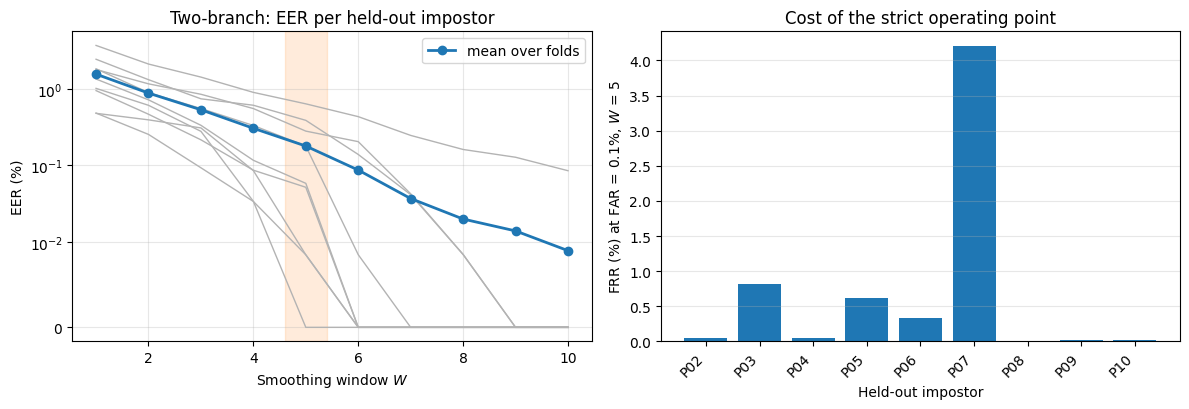


All outputs written to results/two-branch/


In [16]:
# Part 9: Tables, tests and figures
# ---------------------------------------------------------------------------

PUB_PER_FOLD = np.array([0.326, 0.365, 0.649, 1.209, 0.468,
                         2.354, 0.278, 0.365, 0.292])          # published Table 1
FLOOR_NOTE = ("entries at 0.000 mean no error was observed at the resolution of "
              "the test set, not that the error rate is zero")

per_fold = raw.groupby(['fold', 'heldout'], as_index=False).mean(numeric_only=True)
rows = []
for w in SMOOTHING_WINDOWS:
    v = per_fold[f'eer_W{w}'].dropna().values * 100
    f = per_fold[f'frr01_W{w}'].dropna().values * 100
    m, sd = mean_sd(v)
    rows.append({'W': w, 'EER_mean(%)': round(m, 3), 'EER_sd(%)': round(sd, 3),
                 'EER_min(%)': round(v.min(), 3), 'EER_max(%)': round(v.max(), 3),
                 'FRR@0.1%_mean': round(float(f.mean()), 2),
                 'FRR@0.1%_max': round(float(f.max()), 2),
                 'n_folds': len(v), 'at_floor': int((v == 0).sum())})
summary = pd.DataFrame(rows)
summary.to_csv(f'{OUTDIR}/loso_summary.csv', index=False)
per_fold.to_csv(f'{OUTDIR}/loso_per_fold.csv', index=False)

print("=== Table 1, two-branch proposed system ===")
print(summary.to_string(index=False))
print(f"\n note: {FLOOR_NOTE}")

# Two operating points are reported. W = 3 is the primary one: the two-branch
# model reaches several zero-error folds by W = 5, so the W = 5 mean sits close
# to what 1/n of the test set can resolve, whereas W = 3 is comfortably above it.
# W = 3 is also the faster decision, 0.77 s of typing against 1.2 s.
DT_K, T_W_HALF = 232.6, WINDOW_MS / 2.0
print("\n=== Recommended operating points ===")
for w in (3, 5):
    r = summary[summary['W'] == w].iloc[0]
    lat = ((w - 1) * DT_K + T_W_HALF) / 1000.0
    print(f"  W = {w}:  EER {r['EER_mean(%)']:.3f}% (+/- {r['EER_sd(%)']:.3f})   "
          f"FRR@0.1% {r['FRR@0.1%_mean']:.2f}%   latency {lat:.2f} s   "
          f"folds at the resolution floor: {int(r['at_floor'])}/9")

a = per_fold.sort_values('fold')['eer_W5'].values * 100
a3 = per_fold.sort_values('fold')['eer_W3'].values * 100
PUB_PER_FOLD_W3 = np.array([1.276, 1.135, 1.560, 2.849, 1.240,
                            4.779, 1.119, 0.983, 0.788])
stat3, p3 = wilcoxon(a3, PUB_PER_FOLD_W3)
print(f"\n  at W = 3: two-branch {a3.mean():.3f}%   published {PUB_PER_FOLD_W3.mean():.3f}%   "
      f"better in {int((a3 < PUB_PER_FOLD_W3).sum())}/9   p = {p3:.4f}")
stat, p = wilcoxon(a, PUB_PER_FOLD)
print(f"\n=== Against the published single-stream pipeline, W = 5 ===")
print(f"  two-branch {a.mean():.3f}%   published {PUB_PER_FOLD.mean():.3f}%   "
      f"better in {int((a < PUB_PER_FOLD).sum())}/9   p = {p:.4f}")

if len(ctrl):
    cf = ctrl.groupby(['fold', 'heldout'], as_index=False).mean(numeric_only=True)
    c5 = cf.sort_values('fold')['eer_W5'].values * 100
    m, sd = mean_sd(c5)
    stat, pc = wilcoxon(a, c5)
    print(f"\n=== Capacity control, W = 5 ===")
    print(f"  single-stream d=128 : {m:.3f}% (+/- {sd:.3f})")
    print(f"  two-branch  2 x d=64: {a.mean():.3f}%   "
          f"better in {int((a < c5).sum())}/9   p = {pc:.4f}")
    print("  -> " + ("the advantage is the separation, not the parameter count"
                     if a.mean() < m and pc < 0.05 else
                     "the two designs are not separable at this sample size"))

if len(sc):
    print("\n=== Proposed row for Table 2 (single-configuration, 5 seeds) ===")
    cells = []
    for w in (1, 3, 5):
        m, sd = mean_sd(sc[f'eer_W{w}'].values * 100)
        cells.append(f"\\textbf{{{m:.2f}}} ($\\pm$ {sd:.2f})")
    print("\\textbf{CNN-LSTM two-branch (Proposed)} & " + " & ".join(cells) + " \\\\")

if len(sweep):
    print("\n=== Table 3, feature-window sweep ===")
    srows = []
    for tw in SWEEP_WINDOWS:
        sub = sweep[sweep['window_ms'] == tw]
        r = {'T_w(ms)': tw}
        for w in (1, 3, 5):
            m, sd = mean_sd(sub[f'eer_W{w}'].values * 100)
            r[f'W={w}'] = f"{m:.2f} +/- {sd:.2f}"
        srows.append(r)
    stab = pd.DataFrame(srows)
    stab.to_csv(f'{OUTDIR}/window_sweep_summary.csv', index=False)
    print(stab.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for _, r in per_fold.iterrows():
    ax[0].plot(SMOOTHING_WINDOWS,
               [r[f'eer_W{w}'] * 100 for w in SMOOTHING_WINDOWS],
               color='0.7', lw=1)
ax[0].plot(SMOOTHING_WINDOWS, summary['EER_mean(%)'], 'o-', color='C0', lw=2,
           label='mean over folds')
ax[0].axvspan(4.6, 5.4, color='C1', alpha=.15)
ax[0].set_xlabel('Smoothing window $W$'); ax[0].set_ylabel('EER (%)')
ax[0].set_yscale('symlog', linthresh=0.01)
ax[0].set_title('Two-branch: EER per held-out impostor')
ax[0].legend(); ax[0].grid(alpha=.3)

x = np.arange(len(per_fold))
ax[1].bar(x, per_fold.sort_values('fold')['frr01_W5'] * 100, color='C0')
ax[1].set_xticks(x)
ax[1].set_xticklabels(per_fold.sort_values('fold')['heldout'], rotation=45, ha='right')
ax[1].set_ylabel('FRR (%) at FAR = 0.1%, $W$ = 5')
ax[1].set_xlabel('Held-out impostor')
ax[1].set_title('Cost of the strict operating point')
ax[1].grid(axis='y', alpha=.3)
plt.tight_layout()
plt.savefig(f'{OUTDIR}/two_branch_loso.png', dpi=300, bbox_inches='tight')
plt.show()
print(f"\nAll outputs written to {OUTDIR}/")